# E-Commerce Customer Churn Analysis & Prediction Model
This notebook performs Exploratory Data Analysis (EDA) on e-commerce customer data and builds an XGBoost machine learning model to predict customer churn.

In [20]:
!pip install seaborn 
!pip install scikit-learn
!pip install xgboost

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import xgboost as xgb

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set visual style for professional business reports
sns.set_theme(style="whitegrid", palette="muted")
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Dataset
Loading the raw Excel dataset downloaded from Kaggle.

**Dataset URL:** [https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction](https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction)

*Note: Ensure `E Commerce Dataset.xlsx` is in the same directory as this notebook. You may need to run `!pip install openpyxl xgboost scikit-learn` in your terminal.*

In [10]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]


In [11]:
# Load the dataset
df = pd.read_excel('E Commerce Dataset.xlsx', sheet_name='E Comm')

# Display the dataset shape and first 5 rows
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


## 2. Data Cleaning & Preprocessing
Handling missing values and standardizing categorical text to ensure accurate statistical analysis.

In [12]:
# 1. Identify missing values
missing_before = df.isnull().sum()
print("Missing values before cleaning:\n", missing_before[missing_before > 0])

# 2. Fill missing continuous/numerical variables with the median to avoid outlier skew
numeric_cols_with_na = ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'DaySinceLastOrder']
for col in numeric_cols_with_na:
    df[col] = df[col].fillna(df[col].median())

# 3. Fill missing discrete/categorical values with the mode
categorical_cols_with_na = ['CouponUsed', 'OrderCount']
for col in categorical_cols_with_na:
    df[col] = df[col].fillna(df[col].mode()[0])

# 4. Standardize text in categorical columns to prevent duplicate categories
df['PreferredLoginDevice'] = df['PreferredLoginDevice'].replace('Mobile Phone', 'Mobile')
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace(['CC', 'Credit Card'], 'Credit Card')
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace(['COD', 'Cash on Delivery'], 'Cash on Delivery')

# Verify cleaning
print("\nTotal missing values after cleaning:", df.isnull().sum().sum())

Missing values before cleaning:
 Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64

Total missing values after cleaning: 0


## 3. Exploratory Data Analysis (EDA)
Extracting quantitative insights and analyzing how different variables (like complaints and tenure) impact churn rates.

In [13]:
# 1. Overall Churn Rate
churn_rate = df['Churn'].mean() * 100
print(f"Overall Customer Churn Rate: {churn_rate:.2f}%\n")

# 2. Average Tenure by Churn Status
tenure_churn = df.groupby('Churn')['Tenure'].mean()
print("Average Tenure (Months) by Churn Status:")
print(f"Retained (0): {tenure_churn[0]:.2f} Months | Churned (1): {tenure_churn[1]:.2f} Months\n")

# 3. Churn Rate by Complaints
complain_churn = df.groupby('Complain')['Churn'].mean() * 100
print("Churn Rate by Complaints (0 = No, 1 = Yes):")
print(complain_churn.round(2).astype(str) + '%')

# 4. Cashback Amount vs. Churn
cashback_churn = df.groupby('Churn')['CashbackAmount'].mean()
print("\nAverage Cashback Amount by Churn Status:")
print(f"Retained (0): ${cashback_churn[0]:.2f} | Churned (1): ${cashback_churn[1]:.2f}")

Overall Customer Churn Rate: 16.84%

Average Tenure (Months) by Churn Status:
Retained (0): 11.40 Months | Churned (1): 3.86 Months

Churn Rate by Complaints (0 = No, 1 = Yes):
Complain
0    10.93%
1    31.67%
Name: Churn, dtype: object

Average Cashback Amount by Churn Status:
Retained (0): $180.64 | Churned (1): $160.37


## 4. Visualizing Business Insights
Generating a 4-panel dashboard to visualize feature correlations, retention distributions, and category-specific churn probability.

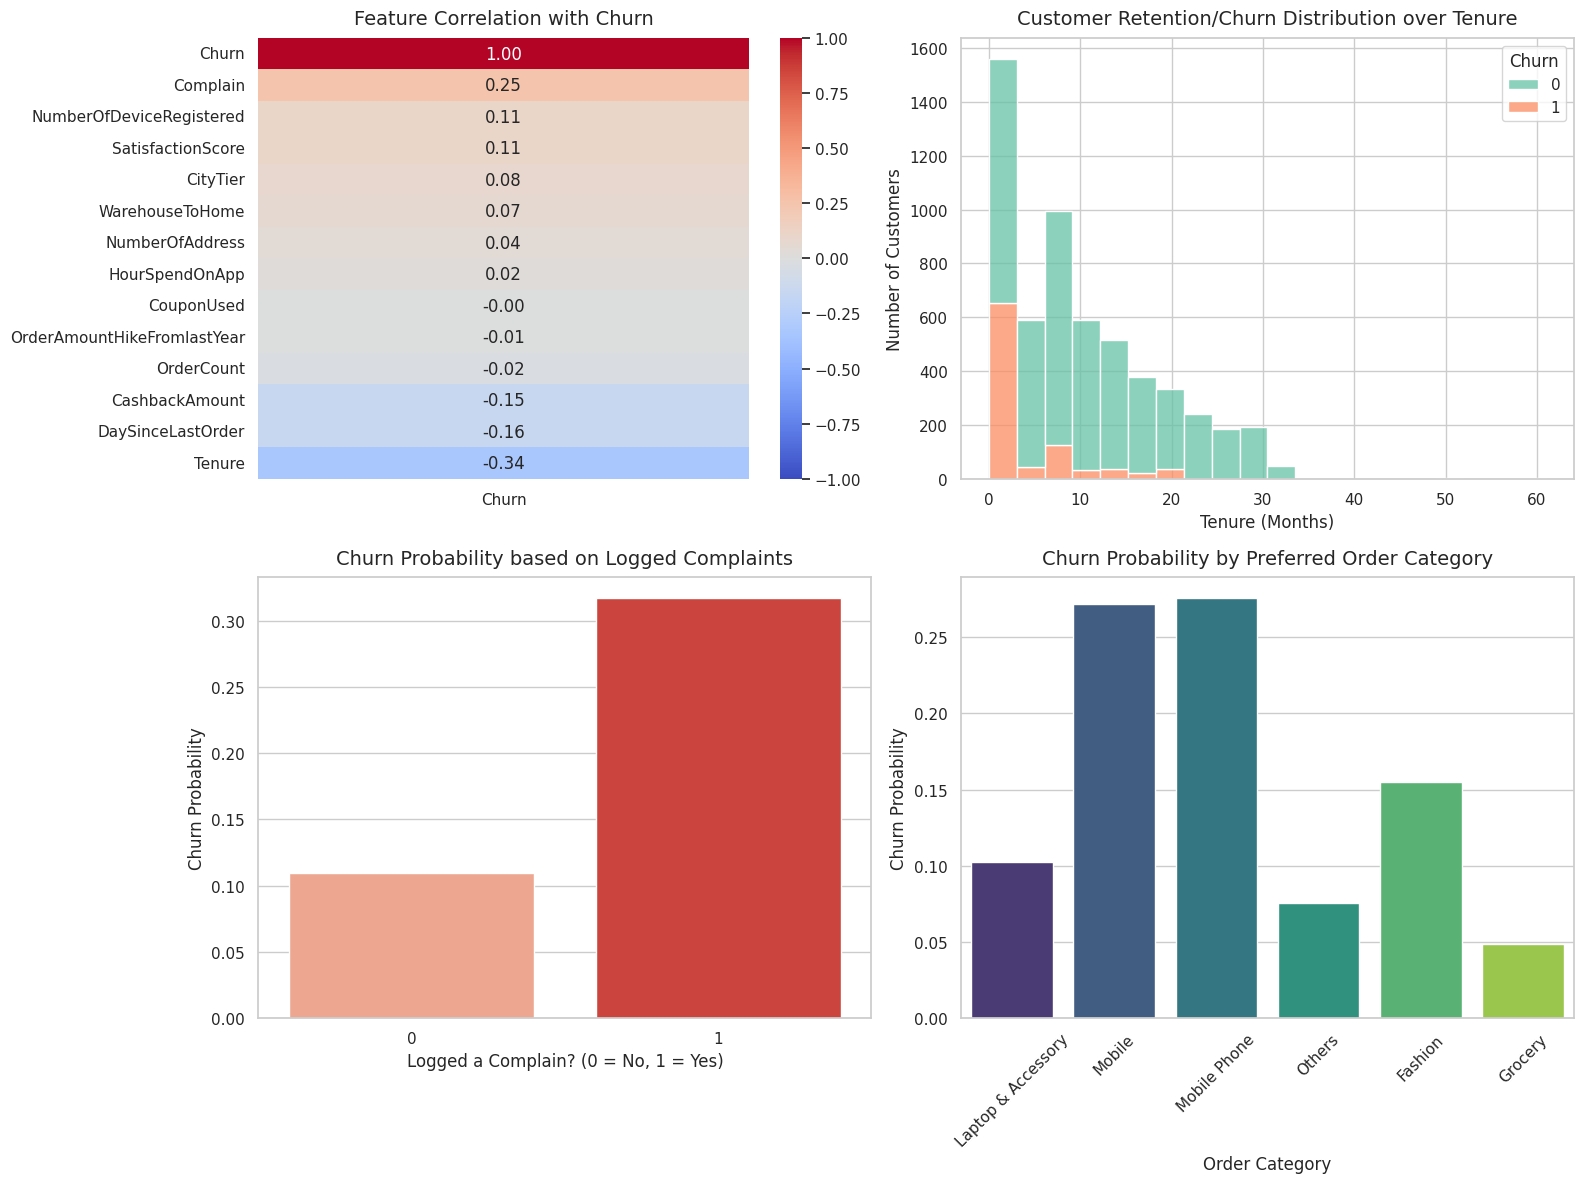

In [14]:
plt.figure(figsize=(16, 12))

# Plot 1: Feature Correlation Heatmap
plt.subplot(2, 2, 1)
# Select only numeric columns and drop CustomerID
numeric_df = df.select_dtypes(include=[np.number]).drop(['CustomerID'], axis=1, errors='ignore')
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix[['Churn']].sort_values(by='Churn', ascending=False), 
            annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature Correlation with Churn", fontsize=14, pad=10)

# Plot 2: Churn Distribution by Tenure
plt.subplot(2, 2, 2)
sns.histplot(data=df, x='Tenure', hue='Churn', multiple="stack", bins=20, palette='Set2')
plt.title("Customer Retention/Churn Distribution over Tenure", fontsize=14, pad=10)
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

# Plot 3: Impact of Complaints on Churn
plt.subplot(2, 2, 3)
sns.barplot(x='Complain', y='Churn', data=df, palette='Reds', errorbar=None)
plt.title("Churn Probability based on Logged Complaints", fontsize=14, pad=10)
plt.xlabel("Logged a Complain? (0 = No, 1 = Yes)")
plt.ylabel("Churn Probability")

# Plot 4: Churn by Preferred Order Category
plt.subplot(2, 2, 4)
sns.barplot(x='PreferedOrderCat', y='Churn', data=df, palette='viridis', errorbar=None)
plt.title("Churn Probability by Preferred Order Category", fontsize=14, pad=10)
plt.xlabel("Order Category")
plt.ylabel("Churn Probability")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 5. Machine Learning Modeling (XGBoost Classifier)
Now we will prepare our dataset for machine learning by encoding categorical variables, splitting the data, and training an XGBoost model to predict customer churn.

Training XGBoost Model...

Model Accuracy: 98.93%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       936
           1       0.98      0.96      0.97       190

    accuracy                           0.99      1126
   macro avg       0.98      0.98      0.98      1126
weighted avg       0.99      0.99      0.99      1126



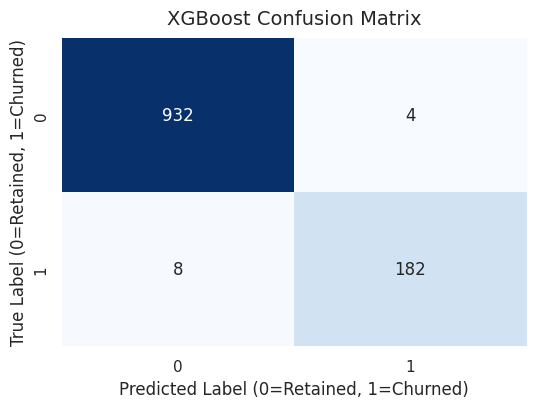

In [15]:
# 1. Feature Engineering & Preprocessing
# Drop CustomerID as it has no predictive value
ml_df = df.drop(['CustomerID'], axis=1, errors='ignore')

# Convert categorical columns into dummy variables (One-Hot Encoding)
ml_df = pd.get_dummies(ml_df, drop_first=True)

# Separate Target (y) and Features (X)
X = ml_df.drop('Churn', axis=1)
y = ml_df['Churn']

# 2. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Initialize and Train XGBoost Classifier
print("Training XGBoost Model...")
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train_scaled, y_train)

# 5. Predictions
y_pred = xgb_model.predict(X_test_scaled)

# 6. Evaluation
print(f"\nModel Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("XGBoost Confusion Matrix", fontsize=14, pad=10)
plt.xlabel("Predicted Label (0=Retained, 1=Churned)")
plt.ylabel("True Label (0=Retained, 1=Churned)")
plt.show()

### Feature Importance
Understanding which features were most influential in the XGBoost model's decision-making process.

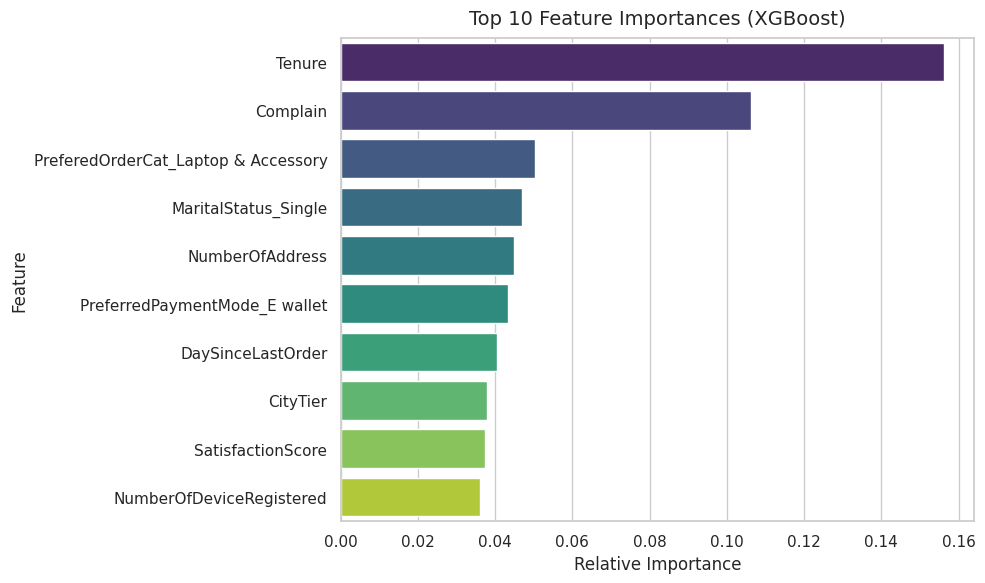

In [16]:
importances = xgb_model.feature_importances_
indices = np.argsort(importances)[::-1][:10] # Get top 10 features

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=X.columns[indices], palette='viridis')
plt.title("Top 10 Feature Importances (XGBoost)", fontsize=14, pad=10)
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Saving Model
Now we have to save our model for deployment

In [18]:
import joblib

# Save the trained XGBoost model
joblib.dump(xgb_model, 'xgboost_churn_model.pkl')

# Save the scaler to normalize frontend inputs
joblib.dump(scaler, 'scaler.pkl')

# Save the expected column names (crucial for matching  variables)
joblib.dump(list(X.columns), 'feature_columns.pkl')

print("Model, scaler, and features successfully saved for deployment!")

Model, scaler, and features successfully saved for deployment!
